# Vivienda social en alquiler sobre el total de viviendas

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "parque-vivienda-publica"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Vivienda social en alquiler sobre el total de viviendas"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del total de viviendas"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Qué parte del parque de viviendas es vivienda social en alquiler: viviendas que se alquilan por debajo del precio de mercado y se adjudican con criterios administrativos, según la definición de la OCDE.

**Cómo se lee.** Un valor de 1 significa que una de cada cien viviendas es vivienda social en alquiler.

**Limitaciones.**
- La OCDE solo publica uno o dos datos por país (hacia 2010 y hacia 2022), con años distintos según el país, por lo que la gráfica muestra puntos sueltos y no series.
- Cada país define la vivienda social a su manera; la OCDE armoniza lo que puede.
- No hay dato para la UE-27 ni media de la OCDE con año exacto.

## 2. Descarga

OECD Affordable Housing Database, indicador PH4.2 (hoja `Table PH4.2.A1`, columna «% of total housing stock», con el año de cada observación).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from datetime import date

from lib import oecd_ahd
from lib.tipos import FuenteMeta

PAISES = {"Spain": "espana", "United States": "eeuu", "Canada": "canada"}
FICHERO = "PH4-2-Social-rental-housing-stock"


def descargar():
    return oecd_ahd.get(FICHERO, "Table PH4.2.A1", columna="% of total housing stock", paises=PAISES, desde=DESDE)


df, fuentes = descargar()

## 3. Transformación

Los datos ya vienen en la unidad final. La UE-27 y la OCDE quedan sin dato, con la fuente consultada.

In [ ]:
hoy = date.today().isoformat()
url = f"{oecd_ahd.BASE}/{FICHERO}.xlsx"
for serie in ("ue27", "ocde"):
    df = pd.concat([df, pd.DataFrame({"serie": [serie], "periodo": [DESDE], "valor": [float("nan")]})], ignore_index=True)
    fuentes.append(FuenteMeta(serie, "OECD", f"Affordable Housing Database, {FICHERO} (consultada: sin dato con año)", url, hoy))

NOTAS = [
    "OECD Affordable Housing Database (PH4.2): viviendas sociales en alquiler en porcentaje del total de viviendas. La OCDE publica uno o dos datos por país, hacia 2010 y hacia 2022, cada uno con su año.",
    "Cada país define la vivienda social a su manera; la OCDE armoniza la definición: alquiler por debajo del precio de mercado, adjudicado con criterios administrativos.",
    "UE-27 y OCDE: la base no publica un dato para la UE-27, y la media de la OCDE solo aparece en una figura sin año exacto; esas series quedan sin dato.",
]

## 4. Visualización

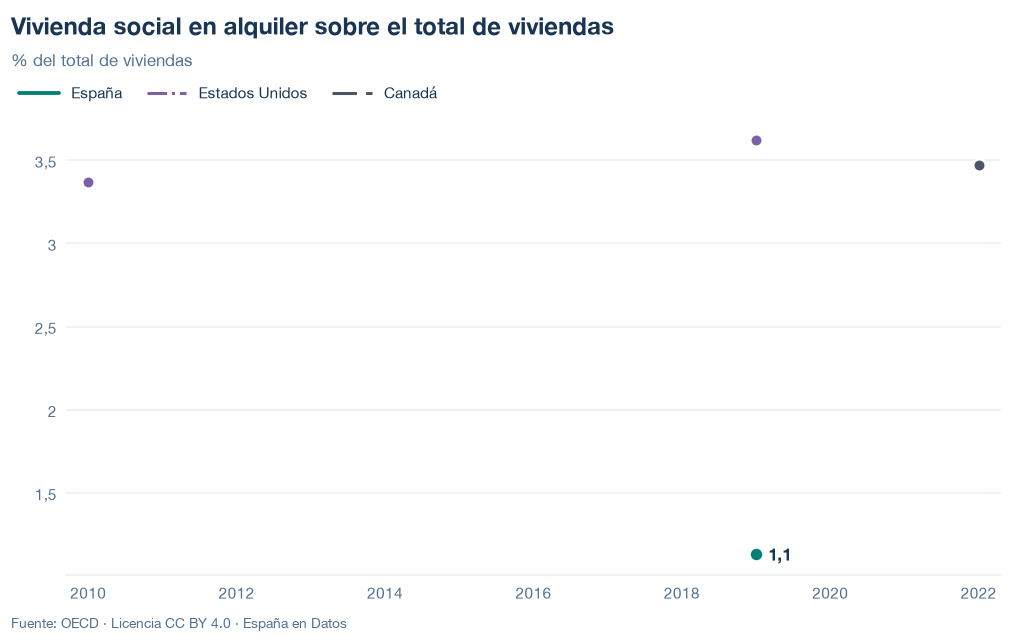

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/parque-vivienda-publica.json y data/parque-vivienda-publica.csv


## 6. Fuentes, notas y licencia

- OECD Affordable Housing Database, PH4.2 (`Table PH4.2.A1`).

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.